# NuSVC
TF-IDF features + NuSVC. Trains on `train.jsonl`, monitors on `val.jsonl`, saves model to Drive.

NuSVC is slower than the others (libsvm, non-linear-time); expect several minutes.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

# ---- EDIT THIS: folder in your Google Drive that contains gujarati_fake_real_combined.jsonl ----
DATA_DIR = "/content/drive/MyDrive/RM_24DCS041_054"
MODEL_DIR = f"{DATA_DIR}/models"
import os; os.makedirs(MODEL_DIR, exist_ok=True)
SEED = 42

Mounted at /content/drive


In [2]:
import pandas as pd, numpy as np
train = pd.read_json(f"{DATA_DIR}/train.jsonl", lines=True, dtype={"news_id": str})
val   = pd.read_json(f"{DATA_DIR}/val.jsonl",   lines=True, dtype={"news_id": str})
test  = pd.read_json(f"{DATA_DIR}/test.jsonl",  lines=True, dtype={"news_id": str})
label2id = {"real": 0, "fake": 1}
id2label = {v: k for k, v in label2id.items()}
X_train, y_train = train["text"].astype(str), train["label"].map(label2id).values
X_val,   y_val   = val["text"].astype(str),   val["label"].map(label2id).values
X_test,  y_test  = test["text"].astype(str),  test["label"].map(label2id).values
print(train.shape, val.shape, test.shape)
print(train["label"].value_counts())

(13003, 3) (2786, 3)
label
fake    7238
real    5765
Name: count, dtype: int64


In [3]:
import joblib, time
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import NuSVC
from sklearn.metrics import accuracy_score, f1_score

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=50000, min_df=2, sublinear_tf=True)),
    ("clf", NuSVC(nu=0.3, kernel="linear", probability=False, random_state=SEED)),
])
t = time.time()
pipe.fit(X_train, y_train)
print(f"Training done in {time.time()-t:.1f}s")
pred = pipe.predict(X_val)
print("Val accuracy:", accuracy_score(y_val, pred), "| Val macro-F1:", f1_score(y_val, pred, average="macro"))
joblib.dump(pipe, f"{MODEL_DIR}/06_nusvc.joblib")
print("Saved.")

Training done in 893.0s
Val accuracy: 0.7910983488872936 | Val macro-F1: 0.7888100805241574
Saved.


In [4]:
from sklearn.metrics import classification_report, recall_score, precision_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("\nTfidfVectorizer Parameters:")
print(f"  ngram_range: {pipe.named_steps['tfidf'].ngram_range}")
print(f"  max_features: {pipe.named_steps['tfidf'].max_features}")
print(f"  min_df: {pipe.named_steps['tfidf'].min_df}")
print(f"  sublinear_tf: {pipe.named_steps['tfidf'].sublinear_tf}")


TfidfVectorizer Parameters:
  ngram_range: (1, 2)
  max_features: 50000
  min_df: 2
  sublinear_tf: True


In [5]:
print("\nNuSVC Parameters:")
print(f"  nu: {pipe.named_steps['clf'].nu}")
print(f"  kernel: {pipe.named_steps['clf'].kernel}")
print(f"  probability: {pipe.named_steps['clf'].probability}")
print(f"  random_state: {pipe.named_steps['clf'].random_state}")


NuSVC Parameters:
  nu: 0.3
  kernel: linear
  probability: False
  random_state: 42


In [6]:
overall_accuracy = accuracy_score(y_val, pred)
overall_recall = recall_score(y_val, pred, average='macro')
overall_precision = precision_score(y_val, pred, average='macro')
overall_f1 = f1_score(y_val, pred, average='macro')

print("\nEvaluation Parameters:")
print(f"  Accuracy Score: {accuracy_score.__name__}")
print(f"  F1 Score (Macro): {f1_score.__name__} with average='macro'")

print(f"\nOverall Accuracy: {overall_accuracy:.4f}")
print(f"Overall Macro Recall: {overall_recall:.4f}")
print(f"Overall Macro Precision: {overall_precision:.4f}")
print(f"Overall Macro F1-score: {overall_f1:.4f}")


Evaluation Parameters:
  Accuracy Score: accuracy_score
  F1 Score (Macro): f1_score with average='macro'

Overall Accuracy: 0.7911
Overall Macro Recall: 0.7894
Overall Macro Precision: 0.7883
Overall Macro F1-score: 0.7888


In [7]:
print("\nClassification Report (Validation Set):")
print(classification_report(y_val, pred, target_names=[id2label[0], id2label[1]]))


Classification Report (Validation Set):
              precision    recall  f1-score   support

        real       0.76      0.77      0.77      1235
        fake       0.82      0.80      0.81      1551

    accuracy                           0.79      2786
   macro avg       0.79      0.79      0.79      2786
weighted avg       0.79      0.79      0.79      2786



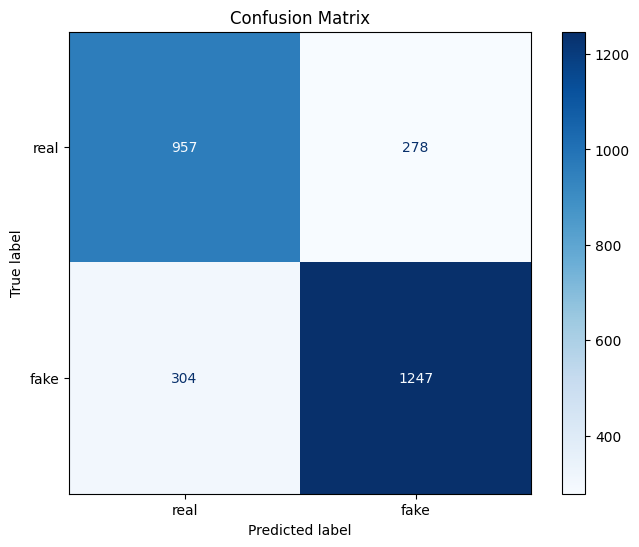

In [8]:
# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=[id2label[0], id2label[1]], cmap=plt.cm.Blues, ax=ax)
ax.set_title("Confusion Matrix")
plt.grid(False)
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Final evaluation on the held-out test split (not used during fitting).
test_pred = pipe.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, test_pred))
print("Test macro precision:", precision_score(y_test, test_pred, average="macro", zero_division=0))
print("Test macro recall:", recall_score(y_test, test_pred, average="macro", zero_division=0))
print("Test macro-F1:", f1_score(y_test, test_pred, average="macro", zero_division=0))
print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=[id2label[0], id2label[1]], zero_division=0))

cm_test = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=[id2label[0], id2label[1]],
            yticklabels=[id2label[0], id2label[1]])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix (Test Set)")
plt.show()
